# ¿Qué es sesgo y varianza en regresión?
* Sesgo:	Es un Error sistemático, indica que el modelo es demasiado simple y no capta la complejidad de los datos (underfitting).
* Varianza:	Indica Sensibilidad al conjunto de entrenamiento, ya que el modelo es muy complejo y se ajusta demasiado (overfitting).

# PASOS PARA DIAGNOSTICAR SESGO Y VARIANZA

1. Analizar el error en entrenamiento y prueba

| Indicador                                               | Diagnóstico                        |
| ------------------------------------------------------- | ---------------------------------- |
| **Alto error en entrenamiento y prueba**            | Alto sesgo (modelo subajusta)      |
| **Bajo error en entrenamiento pero alto en prueba** | Alta varianza (modelo sobreajusta) |
| **Errores similares y bajos**                           | Buen equilibrio                    |


Modelo 1:
Entrenamiento: RMSE = 12.0
Prueba:    RMSE = 28.0  ← gran diferencia entre los valores → Overfitting → alta varianza

Modelo 2:
Entrenamiento: RMSE = 30.0
Prueba:    RMSE = 31.5  ← ambos altos → Underfitting → alto sesgo


2. Visualizar la predicción vs valores reales
Gráfico: y_real vs y_predicho
- Línea perfecta: y = x
- Si los puntos están muy lejos de la diagonal → error alto

Indicadores visuales:
- Distribución dispersa y alejada: Sesgo alto (modelo no aprende).
- Buena alineación solo en entrenamiento: Varianza alta.

3. Analizar los residuos (errores)
* Gráfico: y_pred vs error (residuo)
* Residuos aleatorios: Buen modelo
* Patrón visible o sistemático: Modelo sesgado
* Distribución muy dispersa solo en test: Alta varianza

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.datasets import make_regression

In [2]:
# Dataset de ejemplo
X, y = make_regression(n_samples=200, n_features=1, noise=15, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [3]:
# Modelo
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [4]:
# Predicciones
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

In [5]:
# Residuos
res_train = y_train - y_train_pred
res_test = y_test - y_test_pred

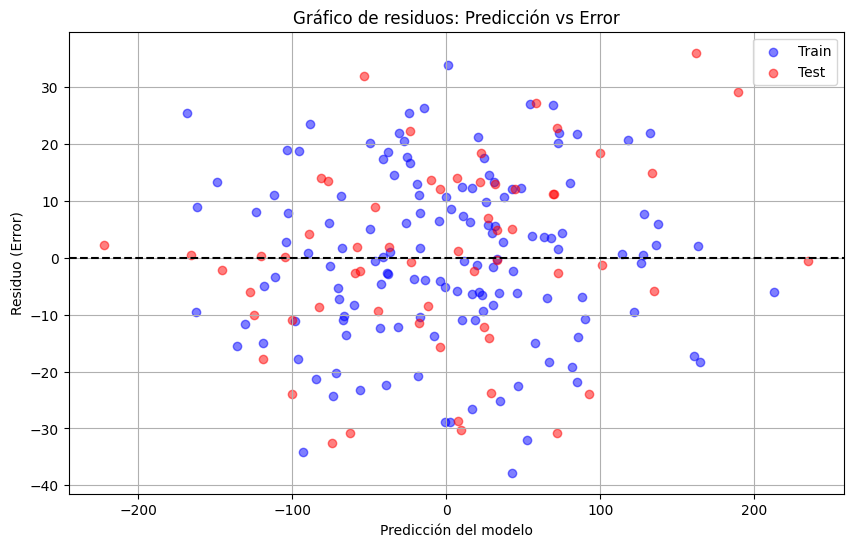

In [6]:
# Gráfico de residuos
plt.figure(figsize=(10, 6))

plt.scatter(y_train_pred, res_train, color='blue', alpha=0.5, label='Train')
plt.scatter(y_test_pred, res_test, color='red', alpha=0.5, label='Test')

plt.axhline(y=0, color='black', linestyle='--')
plt.xlabel('Predicción del modelo')
plt.ylabel('Residuo (Error)')
plt.title('Gráfico de residuos: Predicción vs Error')
plt.legend()
plt.grid(True)
plt.show()

¿Cómo interpretar el gráfico?

| Patrón observado                       | Diagnóstico                      |
| -------------------------------------- | -------------------------------- |
| Nube aleatoria alrededor de 0          | Buen ajuste (bajo sesgo)         |
| Forma curva o patrón visible           | Modelo sesgado (no captura bien) |
| Dispersión alta en test                | Alta varianza (sobreajuste)      |
| Error sistemático en zonas específicas | Mala especificación del modelo   |


4. Curvas de aprendizaje (learning curves)
* Muestran el error (MSE o RMSE) según el tamaño del dataset.

Interpretación Típica

| Gráfico                                        | Diagnóstico   |
| ---------------------------------------------- | ------------- |
| Entrenamiento y validación altos y planos      | Alto sesgo    |
| Entrenamiento bajo, validación alta con brecha | Alta varianza |
| Ambos bajan y convergen                        | Buen modelo   |

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve
from sklearn.linear_model import Ridge
from sklearn.datasets import make_regression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import ShuffleSplit

In [8]:
# Dataset sintético
X, y = make_regression(n_samples=500, n_features=20, noise=10, random_state=42)

In [9]:
# Modelo
model = Ridge(alpha=1.0)

In [10]:
# Cross-validation
cv = ShuffleSplit(n_splits=10, test_size=0.2, random_state=42)

In [11]:
# Curva de aprendizaje
train_sizes, train_scores, val_scores = learning_curve(
    estimator=model,
    X=X,
    y=y,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=cv,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    shuffle=True,
    random_state=42
)

In [12]:
# Convertimos a MSE (positivo)
train_errors = -train_scores
val_errors = -val_scores

In [13]:
# Promedios
train_errors_mean = np.mean(train_errors, axis=1)
val_errors_mean = np.mean(val_errors, axis=1)

In [14]:
# RMSE opcional
train_rmse = np.sqrt(train_errors_mean)
val_rmse = np.sqrt(val_errors_mean)

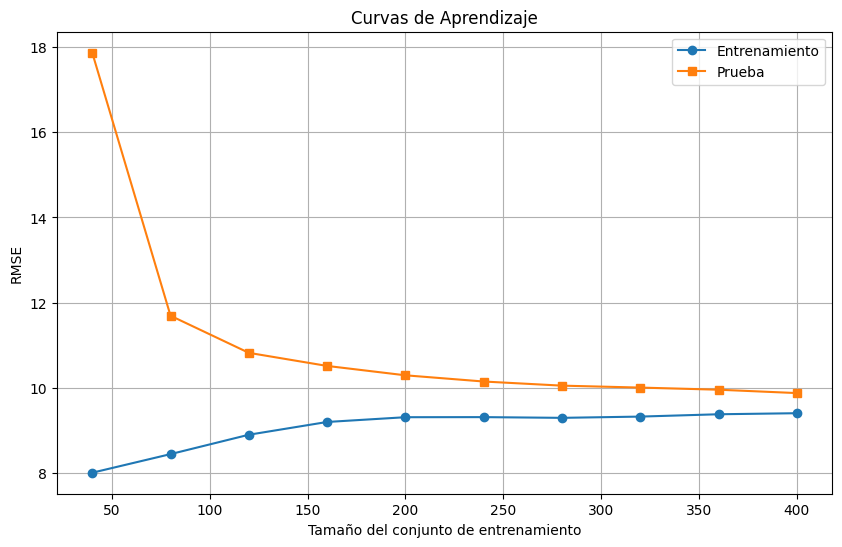

In [15]:
# Gráfico
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_rmse, label='Entrenamiento', marker='o')
plt.plot(train_sizes, val_rmse, label='Prueba', marker='s')
plt.xlabel('Tamaño del conjunto de entrenamiento')
plt.ylabel('RMSE')
plt.title('Curvas de Aprendizaje')
plt.legend()
plt.grid(True)
plt.show()

¿Qué muestran las curvas de aprendizaje?
Las curvas de aprendizaje grafican:
- Error en entrenamiento
- Error en validación cruzada
... en función del tamaño del dataset de entrenamiento.

¿Qué se interpreta?

| Patrón visual observado                   | Diagnóstico     |
| ----------------------------------------- | --------------- |
| Ambos errores altos y planos              | Alto sesgo      |
| Error entrenamiento bajo, validación alto | Alta varianza   |
| Ambos errores bajan y convergen           | Buen modelo     |

Cómo generar curvas para cada caso típico:
- Alto sesgo: Usar un modelo muy simple, como LinearRegression con pocos features no transformados.
- Alta varianza: Usar un modelo muy complejo, como RandomForestRegressor con pocos datos.
- Buen modelo: Aumentar datos, regularizar bien el modelo y hacer buena selección de características.

5. Validación cruzada
* Usar K-Fold CV para ver la estabilidad del error.
* Desviación estándar alta entre folds → alta varianza
* Error promedio alto en todos los folds → sesgo alto

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score, KFold
from sklearn.datasets import make_regression
from sklearn.linear_model import Ridge
from sklearn.metrics import make_scorer, mean_squared_error

In [17]:
# Dataset de regresión
X, y = make_regression(n_samples=300, n_features=10, noise=10, random_state=42)

In [18]:
# Modelo
model = Ridge(alpha=1.0)

In [19]:
# Configurar K-Fold
kf = KFold(n_splits=10, shuffle=True, random_state=42)

In [20]:
# Scoring negativo del MSE (lo convertimos luego a positivo)
mse_scorer = make_scorer(mean_squared_error, greater_is_better=False)
neg_mse_scores = cross_val_score(model, X, y, cv=kf, scoring=mse_scorer)

In [21]:
# Convertimos a MSE positivo
mse_scores = -neg_mse_scores
rmse_scores = np.sqrt(mse_scores)

In [22]:
# Métricas
mean_rmse = np.mean(rmse_scores)
std_rmse = np.std(rmse_scores)

In [23]:
# Imprimir resumen
print(f"RMSE promedio: {mean_rmse:.2f}")
print(f"Desviación estándar (RMSE): {std_rmse:.2f}")

RMSE promedio: 10.55
Desviación estándar (RMSE): 0.79


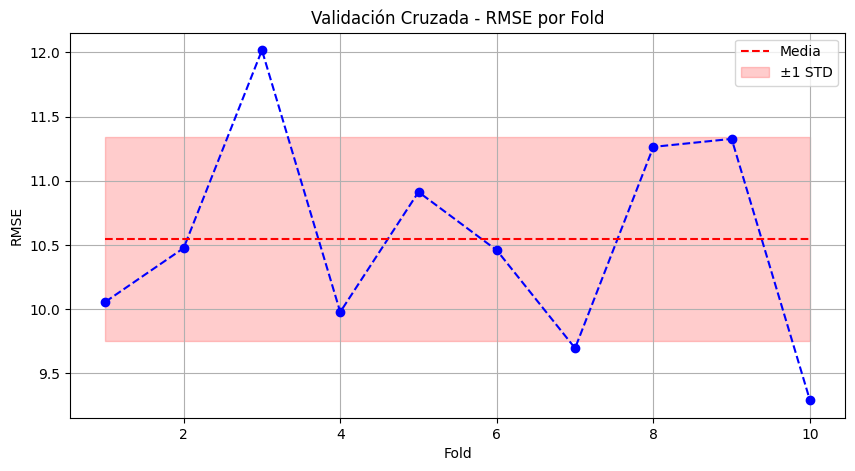

In [24]:
# Gráfico
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(rmse_scores)+1), rmse_scores, marker='o', linestyle='--', color='blue')
plt.hlines(mean_rmse, 1, len(rmse_scores), colors='red', linestyles='dashed', label='Media')
plt.fill_between(range(1, len(rmse_scores)+1),
                 mean_rmse - std_rmse,
                 mean_rmse + std_rmse,
                 color='red', alpha=0.2, label='±1 STD')
plt.title('Validación Cruzada - RMSE por Fold')
plt.xlabel('Fold')
plt.ylabel('RMSE')
plt.legend()
plt.grid(True)
plt.show()

¿Qué podemos observar?

| Indicador                                  | Diagnóstico      |
| ------------------------------------------ | ---------------- |
| **Desviación estándar alta**               | Alta varianza    |
| **Error promedio alto en todos los folds** | Alto sesgo       |
| **Error bajo y estable**                   | Buen modelo      |

¿Cómo interpretarlo?

Diagnóstico visual:
- Todos los errores altos → el modelo no se ajusta bien → alto sesgo
- Errores muy dispares entre folds → el modelo no generaliza bien → alta varianza
- Errores bajos y similares entre folds → modelo bien balanceado

# Resumen

| Síntoma                           | Diagnóstico   | Posible solución                               |
| --------------------------------- | ------------- | ---------------------------------------------- |
| Error alto en train y test        | Alto sesgo    | Modelos más complejos (polinomiales, Boosting) |
| Error bajo en train, alto en test | Alta varianza | Regularización, Bagging, más datos             |
| Error bajo y similar en ambos     | Buen modelo   | No tocar mucho, quizá ajuste fino              |
